![Logs, Metrics, Traces, Spans](assets/banner-adv-01.svg)

Observability vocabulary is easy to memorize and hard to *feel*. So we take one small function, a weather assistant, and look at it through each signal in turn. Every chart and table below is produced by running the code, not drawn by hand.

Nothing here needs a backend. All telemetry stays in memory so you can see the raw data structures.

## The function under observation

A user asks *"What's the weather in Paris, and should I carry an umbrella?"* The assistant does three things:

| Step | What it does | What can go wrong |
|---|---|---|
| `search_docs` | Finds policy snippets mentioning the question's keywords | Returns nothing, or the wrong document |
| `get_weather` | Calls a weather API | Slow (1.4 s sometimes), or times out (15% of calls) |
| `call_llm` | Asks `gpt-4o-mini` to answer using that context | Slow, expensive, or simply wrong |

The tool helpers live in `lab.py` so this notebook can focus on instrumentation.

In [1]:
import random

from openai import OpenAI

from lab import build_messages, get_weather_impl, search_docs_impl

random.seed(7)
client = OpenAI()
MODEL = "gpt-4o-mini"


def answer_question(question: str, city: str) -> str:
    docs = search_docs_impl(question)
    weather = get_weather_impl(city)
    response = client.chat.completions.create(
        model=MODEL, messages=build_messages(question, docs, weather), max_tokens=80
    )
    return response.choices[0].message.content


print(answer_question("What's the weather in Paris, and should I carry an umbrella?", "Paris"))

The weather in Paris is 14°C with a 70% chance of rain, so you should carry an umbrella.


It works. But when it is slow, fails, or answers badly in production, this code tells us nothing. Let's add each signal.

---

## Signal 1: Logs

A **log** is a timestamped record of a discrete event. Structured logs (JSON instead of free text) are searchable by field. We emit one line per step.

In [2]:
import json
import logging
import sys
import threading
import time


class JsonFormatter(logging.Formatter):
    def format(self, record):
        payload = {
            "ts": time.strftime("%H:%M:%S", time.localtime(record.created)) + f".{int(record.msecs):03d}",
            "level": record.levelname,
            "msg": record.getMessage(),
            **getattr(record, "fields", {}),
        }
        return json.dumps(payload)


log = logging.getLogger("weather-agent")
log.handlers.clear()
handler = logging.StreamHandler(sys.stdout)
handler.setFormatter(JsonFormatter())
log.addHandler(handler)
log.setLevel(logging.INFO)
log.propagate = False


def answer_question_logged(question: str, city: str) -> str:
    log.info("request received", extra={"fields": {"city": city}})
    docs = search_docs_impl(question)
    log.info("docs retrieved", extra={"fields": {"count": len(docs)}})
    try:
        weather = get_weather_impl(city)
    except TimeoutError as e:
        log.error("weather failed", extra={"fields": {"error": str(e)}})
        raise
    log.info("weather fetched", extra={"fields": {"rain": weather["rain_chance"]}})
    response = client.chat.completions.create(
        model=MODEL, messages=build_messages(question, docs, weather), max_tokens=80
    )
    log.info("llm answered", extra={"fields": {"tokens": response.usage.total_tokens}})
    return response.choices[0].message.content


answer_question_logged("Should I carry an umbrella in Paris?", "Paris");

{"ts": "18:35:15.467", "level": "INFO", "msg": "request received", "city": "Paris"}


{"ts": "18:35:15.599", "level": "INFO", "msg": "docs retrieved", "count": 1}


{"ts": "18:35:15.853", "level": "INFO", "msg": "weather fetched", "rain": 70}


{"ts": "18:35:16.498", "level": "INFO", "msg": "llm answered", "tokens": 97}


For a single request this reads beautifully. Now serve three users at once, which is what production looks like.

In [3]:
from concurrent.futures import ThreadPoolExecutor

questions = [
    ("Do I need an umbrella in London?", "London"),
    ("Is a jacket needed in Tokyo?", "Tokyo"),
    ("Umbrella for Dubai?", "Dubai"),
]
with ThreadPoolExecutor(max_workers=3) as pool:
    futures = [pool.submit(answer_question_logged, q, c) for q, c in questions]
    for f in futures:
        try:
            f.result()
        except TimeoutError:
            pass

{"ts": "18:35:16.506", "level": "INFO", "msg": "request received", "city": "London"}


{"ts": "18:35:16.506", "level": "INFO", "msg": "request received", "city": "Tokyo"}


{"ts": "18:35:16.506", "level": "INFO", "msg": "request received", "city": "Dubai"}


{"ts": "18:35:16.632", "level": "INFO", "msg": "docs retrieved", "count": 1}


{"ts": "18:35:16.635", "level": "INFO", "msg": "docs retrieved", "count": 1}


...

{"ts": "18:35:16.949", "level": "INFO", "msg": "weather fetched", "rain": 20}


{"ts": "18:35:17.622", "level": "INFO", "msg": "llm answered", "tokens": 103}


{"ts": "18:35:18.038", "level": "INFO", "msg": "weather fetched", "rain": 0}


{"ts": "18:35:18.041", "level": "ERROR", "msg": "weather failed", "error": "weather API timed out for London"}


{"ts": "18:35:18.938", "level": "INFO", "msg": "llm answered", "tokens": 97}


> **The problem.** Lines from three requests are interleaved. Which `llm answered` belongs to London? Which request did the `weather failed` line (if any) break? Logs record *what* happened, but on their own they do not tell you *which journey* each event belongs to. Keep that in mind; traces fix it, and at the end of this notebook we stamp every log line with a `trace_id`.

---

## Signal 2: Metrics

A **metric** is a number aggregated over time: counts, sums, distributions. Metrics are cheap to store and perfect for dashboards and alerts. We use the OpenTelemetry metrics API with an in-memory reader so we can inspect exactly what gets recorded.

| Instrument | Type | Question it answers |
|---|---|---|
| `agent.requests` | Counter | How many requests, and how many failed? |
| `agent.duration` | Histogram | How long do requests take (p50, p95)? |
| `gen_ai.client.token.usage` | Counter | How many tokens are we burning? |

In [4]:
from opentelemetry.sdk.metrics import MeterProvider
from opentelemetry.sdk.metrics.export import InMemoryMetricReader

reader = InMemoryMetricReader()
meter = MeterProvider(metric_readers=[reader]).get_meter("weather-agent")

requests_counter = meter.create_counter("agent.requests", unit="1")
duration_hist = meter.create_histogram("agent.duration", unit="s")
token_counter = meter.create_counter("gen_ai.client.token.usage", unit="token")

durations = []


def answer_question_metered(question: str, city: str) -> str | None:
    start = time.perf_counter()
    status = "ok"
    try:
        docs = search_docs_impl(question)
        weather = get_weather_impl(city)
        response = client.chat.completions.create(
            model=MODEL, messages=build_messages(question, docs, weather), max_tokens=80
        )
        token_counter.add(response.usage.prompt_tokens, {"gen_ai.token.type": "input"})
        token_counter.add(response.usage.completion_tokens, {"gen_ai.token.type": "output"})
        return response.choices[0].message.content
    except TimeoutError:
        status = "error"
    finally:
        elapsed = time.perf_counter() - start
        durations.append((city, status, elapsed))
        requests_counter.add(1, {"status": status})
        duration_hist.record(elapsed, {"status": status})


workload = [(f"Should I carry an umbrella in {c}?", c) for c in ["Paris", "Tokyo", "London", "Dubai"] * 4]
with ThreadPoolExecutor(max_workers=4) as pool:
    list(pool.map(lambda qc: answer_question_metered(*qc), workload))

print(f"ran {len(workload)} requests")

ran 16 requests


Here is what the metrics pipeline actually holds. Notice there is no question text, no city, no answer. Just aggregates.

In [5]:
import pandas as pd

points = []
for rm in reader.get_metrics_data().resource_metrics:
    for sm in rm.scope_metrics:
        for m in sm.metrics:
            for p in m.data.data_points:
                value = getattr(p, "value", None)
                if value is None:
                    value = f"count={p.count}, sum={p.sum:.2f}s, min={p.min:.2f}s, max={p.max:.2f}s"
                points.append({"metric": m.name, "attributes": dict(p.attributes), "value": value})
pd.DataFrame(points)

,metric,attributes,value
0,agent.requests,{'status': 'error'},5
1,agent.requests,{'status': 'ok'},11
2,agent.duration,{'status': 'error'},"count=5, sum=2.47s, min=0.44s, max=0.59s"
3,agent.duration,{'status': 'ok'},"count=11, sum=17.26s, min=1.01s, max=2.35s"
4,gen_ai.client.token.usage,{'gen_ai.token.type': 'input'},869
5,gen_ai.client.token.usage,{'gen_ai.token.type': 'output'},206


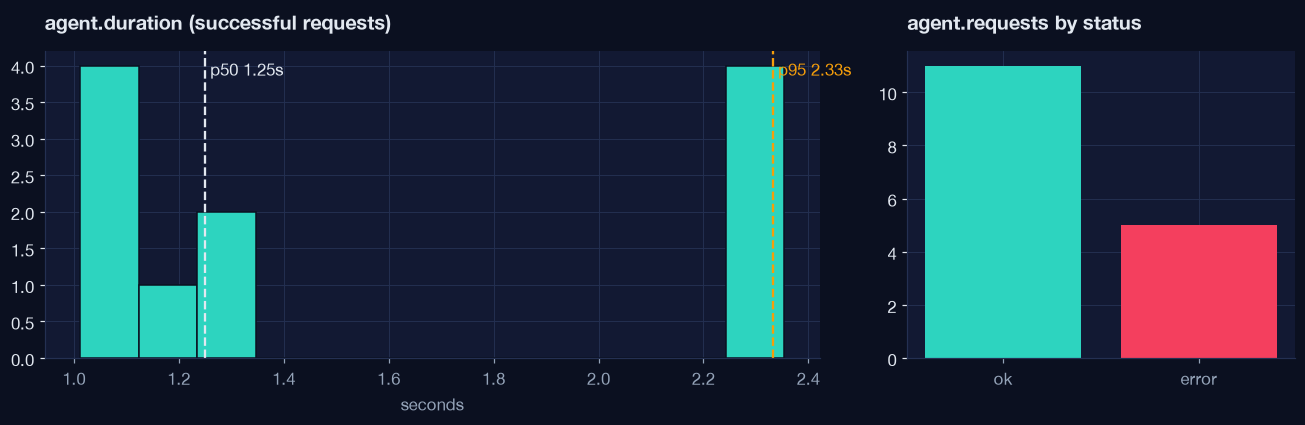

In [6]:
import matplotlib.pyplot as plt
import numpy as np

d = pd.DataFrame(durations, columns=["city", "status", "seconds"])
ok = d[d.status == "ok"]["seconds"]
p50, p95 = np.percentile(ok, 50), np.percentile(ok, 95)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [2, 1]})
axes[0].hist(ok, bins=12, color="#2DD4BF", edgecolor="#0B1020")
for value, name, color in [(p50, "p50", "#E2E8F0"), (p95, "p95", "#F59E0B")]:
    axes[0].axvline(value, color=color, linestyle="--", linewidth=1.5)
    axes[0].text(value, axes[0].get_ylim()[1] * 0.92, f" {name} {value:.2f}s", color=color)
axes[0].set_title("agent.duration (successful requests)")
axes[0].set_xlabel("seconds")
counts = d["status"].value_counts().reindex(["ok", "error"], fill_value=0)
axes[1].bar(counts.index, counts.values, color=["#2DD4BF", "#F43F5E"])
axes[1].set_title("agent.requests by status")
plt.tight_layout()
plt.show()

Metrics tell us **that** p95 latency is several times p50, and **that** some requests fail. They cannot tell us **why** a given request was slow. Was it the weather API or the model? For that we need the shape of each individual request.

---

## Signal 3 and 4: Traces and spans

A **span** is one timed operation: a name, a start and end time, a parent, attributes, events and a status.
A **trace** is the tree of spans that share one `trace_id`, describing one request end to end.

We use the OpenTelemetry tracing API and an in-memory exporter. `start_as_current_span` makes each new span a child of whatever span is currently active, which is how the tree builds itself.

In [7]:
from opentelemetry import trace
from opentelemetry.sdk.resources import Resource
from opentelemetry.sdk.trace import TracerProvider
from opentelemetry.sdk.trace.export import SimpleSpanProcessor
from opentelemetry.sdk.trace.export.in_memory_span_exporter import InMemorySpanExporter
from opentelemetry.trace import Status, StatusCode

exporter = InMemorySpanExporter()
provider = TracerProvider(resource=Resource.create({"service.name": "weather-agent"}))
provider.add_span_processor(SimpleSpanProcessor(exporter))
tracer = provider.get_tracer("weather-agent")


def answer_question_traced(question: str, city: str) -> str:
    with tracer.start_as_current_span("invoke_agent weather-agent") as root:
        root.set_attribute("gen_ai.operation.name", "invoke_agent")
        root.set_attribute("city", city)

        with tracer.start_as_current_span("retrieval docs") as span:
            span.set_attribute("gen_ai.operation.name", "retrieval")
            docs = search_docs_impl(question)
            span.set_attribute("retrieval.documents.count", len(docs))

        with tracer.start_as_current_span("execute_tool get_weather") as span:
            span.set_attribute("gen_ai.operation.name", "execute_tool")
            span.set_attribute("gen_ai.tool.name", "get_weather")
            for attempt in range(3):
                try:
                    weather = get_weather_impl(city)
                    break
                except TimeoutError as e:
                    span.add_event("retry", {"attempt": attempt + 1, "error": str(e)})
            else:
                span.set_status(Status(StatusCode.ERROR, "weather unavailable"))
                raise TimeoutError("weather unavailable")

        with tracer.start_as_current_span(f"chat {MODEL}") as span:
            span.set_attribute("gen_ai.operation.name", "chat")
            span.set_attribute("gen_ai.provider.name", "openai")
            span.set_attribute("gen_ai.request.model", MODEL)
            response = client.chat.completions.create(
                model=MODEL, messages=build_messages(question, docs, weather), max_tokens=80
            )
            span.set_attribute("gen_ai.usage.input_tokens", response.usage.prompt_tokens)
            span.set_attribute("gen_ai.usage.output_tokens", response.usage.completion_tokens)
        return response.choices[0].message.content


random.seed(3)
exporter.clear()
answer_question_traced("What's the weather in London, and should I carry an umbrella?", "London")
spans = exporter.get_finished_spans()
print(f"{len(spans)} spans, all in trace {spans[0].context.trace_id:032x}")

4 spans, all in trace 216363698b529b4a97b750923ceb3ffd


### The raw data

This is everything a backend receives about each span. Look at `parent`: it is how four flat records become a tree.

In [8]:
def to_frame(spans):
    t0 = min(s.start_time for s in spans)
    by_id = {s.context.span_id: s for s in spans}

    def depth(s):
        n = 0
        while s.parent is not None and s.parent.span_id in by_id:
            s = by_id[s.parent.span_id]
            n += 1
        return n

    rows = []
    for s in spans:
        attrs = dict(s.attributes)
        tokens = attrs.get("gen_ai.usage.input_tokens", 0) + attrs.get("gen_ai.usage.output_tokens", 0)
        kind = {"invoke_agent": "agent", "retrieval": "retriever", "execute_tool": "tool", "chat": "generation"}
        rows.append(
            {
                "name": s.name,
                "span_id": f"{s.context.span_id:016x}",
                "parent": f"{s.parent.span_id:016x}" if s.parent else "(root)",
                "kind": kind.get(attrs.get("gen_ai.operation.name"), "span"),
                "start": (s.start_time - t0) / 1e9,
                "duration": (s.end_time - s.start_time) / 1e9,
                "depth": depth(s),
                "events": len(s.events),
                "status": s.status.status_code.name,
                "error": s.status.status_code == StatusCode.ERROR,
                "label": f"{(s.end_time - s.start_time) / 1e6:.0f} ms" + (f"  ·  {tokens} tok" if tokens else "")
                + (f"  ·  {len(s.events)} retries" if s.events else ""),
            }
        )
    return pd.DataFrame(rows).sort_values("start")


frame = to_frame(spans)
frame[["name", "span_id", "parent", "kind", "duration", "events", "status"]].style.format(
    {"duration": "{:.3f}s"}
).hide(axis="index")

name,span_id,parent,kind,duration,events,status
invoke_agent weather-agent,ea7b5bf55eb561a4,(root),agent,1.287s,0,UNSET
retrieval docs,795b929e9a9a80fd,ea7b5bf55eb561a4,retriever,0.206s,0,UNSET
execute_tool get_weather,9b08923d10c67fd9,ea7b5bf55eb561a4,tool,0.255s,0,UNSET
chat gpt-4o-mini,42650644781f9c58,ea7b5bf55eb561a4,generation,0.826s,0,UNSET


### The same data, drawn the way every tracing UI draws it

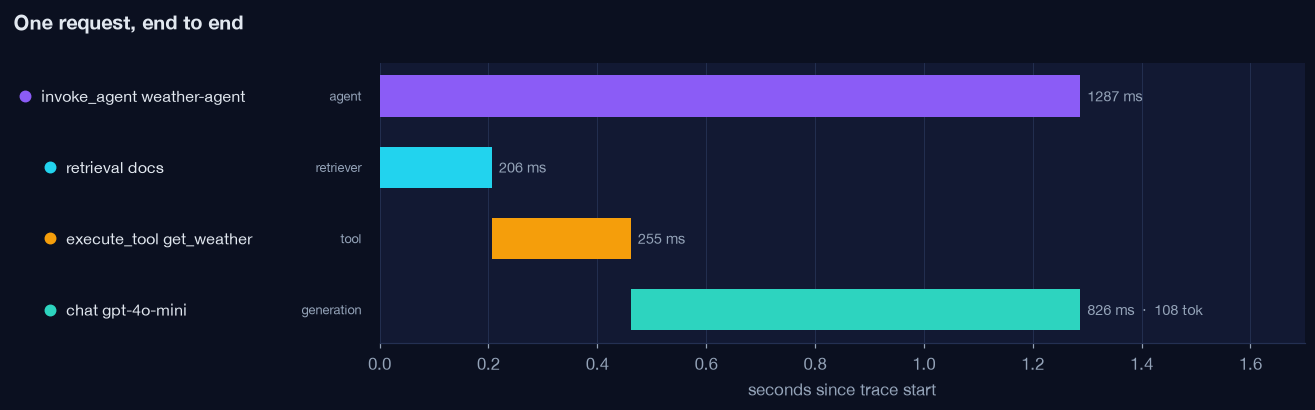

In [9]:
from lab import waterfall

waterfall(frame, "One request, end to end")

Now the question metrics could not answer has an answer: you can see exactly which step dominated this request, and whether a retry happened.

### Anatomy of a single span

Here is the LLM span exactly as OpenTelemetry serializes it. Every observability backend stores something with this shape, whatever they call it.

In [10]:
llm_span = next(s for s in spans if s.name.startswith("chat"))
print(llm_span.to_json(indent=2))

{
  "name": "chat gpt-4o-mini",
  "context": {
    "trace_id": "0x216363698b529b4a97b750923ceb3ffd",
    "span_id": "0x42650644781f9c58",
    "trace_state": "[]"
  },
  "kind": "SpanKind.INTERNAL",
  "parent_id": "0xea7b5bf55eb561a4",
  "start_time": "2026-10-21T01:35:25.227109Z",
  "end_time": "2026-10-21T01:35:26.052667Z",
  "status": {
    "status_code": "UNSET"
  },
  "attributes": {
    "gen_ai.operation.name": "chat",
    "gen_ai.provider.name": "openai",
    "gen_ai.request.model": "gpt-4o-mini",
    "gen_ai.usage.input_tokens": 84,
    "gen_ai.usage.output_tokens": 24
  },
  "events": [],
  "links": [],
  "resource": {
    "attributes": {
      "telemetry.sdk.language": "python",
      "telemetry.sdk.name": "opentelemetry",
      "telemetry.sdk.version": "1.45.1",
      "service.instance.id": "94898639-09d3-4af6-8708-f20b6ce44307",
      "service.name": "weather-agent"
    },
    "schema_url": ""
  }
}


---

## Bringing it together: logs with trace context

Remember the interleaved logs? The fix is to stamp each log line with the active `trace_id` and `span_id`. Now any log line links back to its trace, and you can filter a log search down to one request.

In [11]:
class TraceContextFilter(logging.Filter):
    def filter(self, record):
        ctx = trace.get_current_span().get_span_context()
        fields = getattr(record, "fields", {})
        if ctx.is_valid:
            fields = {"trace_id": f"{ctx.trace_id:032x}"[:12], "span_id": f"{ctx.span_id:016x}"[:8], **fields}
        record.fields = fields
        return True


log.addFilter(TraceContextFilter())


def answer_question_correlated(question: str, city: str):
    with tracer.start_as_current_span("invoke_agent weather-agent"):
        log.info("request received", extra={"fields": {"city": city}})
        with tracer.start_as_current_span("execute_tool get_weather"):
            weather = get_weather_impl(city, flaky=False)
            log.info("weather fetched", extra={"fields": {"rain": weather["rain_chance"]}})
        log.info("done")


with ThreadPoolExecutor(max_workers=3) as pool:
    list(pool.map(lambda qc: answer_question_correlated(*qc), questions))

{"ts": "18:35:26.150", "level": "INFO", "msg": "request received", "trace_id": "fee294763116", "span_id": "78633074", "city": "London"}


{"ts": "18:35:26.151", "level": "INFO", "msg": "request received", "trace_id": "79f248b08cb4", "span_id": "a399f82a", "city": "Tokyo"}


{"ts": "18:35:26.151", "level": "INFO", "msg": "request received", "trace_id": "a2863a7f3b5f", "span_id": "de383784", "city": "Dubai"}


{"ts": "18:35:26.406", "level": "INFO", "msg": "weather fetched", "trace_id": "79f248b08cb4", "span_id": "03e0a813", "rain": 20}


{"ts": "18:35:26.407", "level": "INFO", "msg": "weather fetched", "trace_id": "a2863a7f3b5f", "span_id": "c21b6092", "rain": 0}


{"ts": "18:35:26.409", "level": "INFO", "msg": "done", "trace_id": "79f248b08cb4", "span_id": "a399f82a"}


{"ts": "18:35:26.410", "level": "INFO", "msg": "done", "trace_id": "a2863a7f3b5f", "span_id": "de383784"}


{"ts": "18:35:27.551", "level": "INFO", "msg": "weather fetched", "trace_id": "fee294763116", "span_id": "85ef3430", "rain": 85}


{"ts": "18:35:27.553", "level": "INFO", "msg": "done", "trace_id": "fee294763116", "span_id": "78633074"}


Still interleaved, but now every line carries its `trace_id`, so grouping by it reconstructs each request. Notice `span_id` changes inside the tool call: the log knows exactly which step it came from.

## Summary

| Signal | Unit | Great for | Blind spot |
|---|---|---|---|
| **Logs** | one event | Detail, error messages, audit | Hard to group by request without trace context |
| **Metrics** | an aggregate number | Dashboards, alerts, trends, SLOs | No per-request detail; cannot explain *why* |
| **Traces** | one request | Where time and money went, which step failed | Volume; usually sampled at scale |
| **Spans** | one step in a request | Inputs, outputs, tokens, errors per step | Only useful with their parent trace |

In practice you use all of them together, linked by `trace_id`. Next, [02 OpenTelemetry](02_opentelemetry_in_depth.ipynb) looks at how the SDK, processors and exporters move these spans out of your process.